In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.4f}".format)

sns.set_theme(style="whitegrid")

print("Environment ready!")

Environment ready!


Step 1: Load the dataset

In [51]:
df = pd.read_csv("../data/winequality-red.csv", sep=";")

df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4000,0.7000,0.0000,1.9000,0.0760,11.0000,34.0000,0.9978,3.5100,0.5600,9.4000,5
1,7.8000,0.8800,0.0000,2.6000,0.0980,25.0000,67.0000,0.9968,3.2000,0.6800,9.8000,5
2,7.8000,0.7600,0.0400,2.3000,0.0920,15.0000,54.0000,0.9970,3.2600,0.6500,9.8000,5
3,11.2000,0.2800,0.5600,1.9000,0.0750,17.0000,60.0000,0.9980,3.1600,0.5800,9.8000,6
4,7.4000,0.7000,0.0000,1.9000,0.0760,11.0000,34.0000,0.9978,3.5100,0.5600,9.4000,5


Step 2: Inspect the dataset

In [52]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDescibe:")
print(df.describe())

# Check duplicates
print("Duplicate rows:", df.duplicated().sum())
df[df.duplicated()].head()

# Check the numerical ranges
print("\nNumerical Ranges:")
for col in df.columns:
    print(f"{col}: {df[col].min()} to {df[col].max()}")


Shape: (1599, 12)

Columns:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']

Data types:
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object

Missing values:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Descibe:
       fixed acidity  vola

Let's investigate the duplicates

In [53]:
print("Original dataset size:", len(df))
print("Duplicate rows:", df.duplicated().sum())
print("Unique rows:", df.drop_duplicates().shape[0])

print("\nQuality distribution - Original:")
print(df["quality"].value_counts().sort_index())

df_clean = df.drop_duplicates().copy()

print("\nQuality distribution - After removing duplicates:")
print(df_clean["quality"].value_counts().sort_index())

Original dataset size: 1599
Duplicate rows: 240
Unique rows: 1359

Quality distribution - Original:
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64

Quality distribution - After removing duplicates:
quality
3     10
4     53
5    577
6    535
7    167
8     17
Name: count, dtype: int64


In [54]:
print("Original mean quality:", df["quality"].mean())
print("Cleaned mean quality:", df_clean["quality"].mean())

print("Original mean alcohol:", df["alcohol"].mean())
print("Cleaned mean alcohol:", df_clean["alcohol"].mean())

Original mean quality: 5.6360225140712945
Cleaned mean quality: 5.6232523914643116
Original mean alcohol: 10.422983114446529
Cleaned mean alcohol: 10.432315428010792


Check the quality distribution

In [55]:
print(df_clean["quality"].value_counts().sort_index())

quality
3     10
4     53
5    577
6    535
7    167
8     17
Name: count, dtype: int64


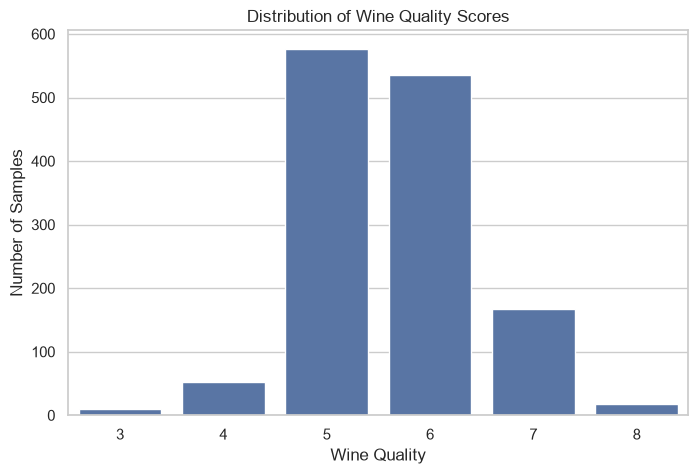

In [56]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x="quality"
)

plt.title("Distribution of Wine Quality Scores")
plt.xlabel("Wine Quality")
plt.ylabel("Number of Samples")
plt.show()

Check distributions of the main numerical variables

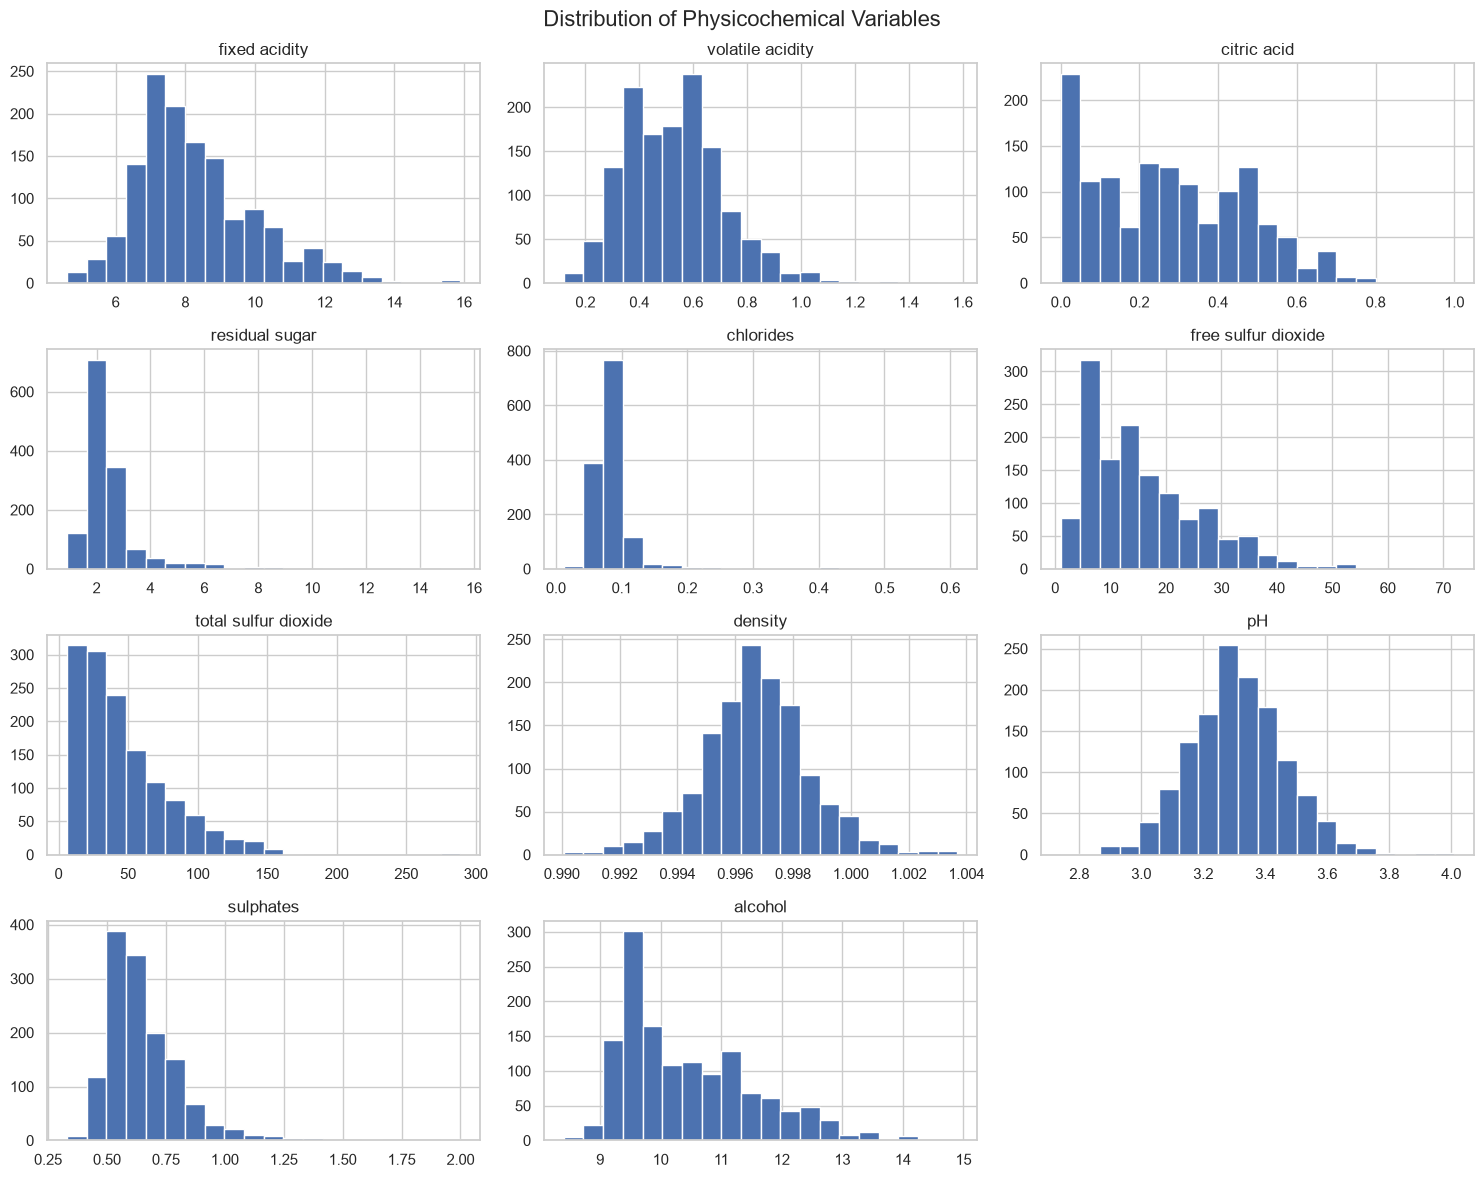

In [57]:
features = [
    "fixed acidity",
    "volatile acidity",
    "citric acid",
    "residual sugar",
    "chlorides",
    "free sulfur dioxide",
    "total sulfur dioxide",
    "density",
    "pH",
    "sulphates",
    "alcohol"
]

df_clean[features].hist(
    figsize=(15, 12),
    bins=20
)

plt.suptitle("Distribution of Physicochemical Variables", fontsize=16)
plt.tight_layout()
plt.show()

Calculate skewness and kurtosis

In [58]:
stats_table = pd.DataFrame({
    "Mean": df_clean[features].mean(),
    "Median": df_clean[features].median(),
    "Variance": df_clean[features].var(),
    "Std Dev": df_clean[features].std(),
    "Minimum": df_clean[features].min(),
    "Maximum": df_clean[features].max(),
    "Range": df_clean[features].max() - df_clean[features].min(),
    "Q1": df_clean[features].quantile(0.25),
    "Q3": df_clean[features].quantile(0.75),
    "IQR": df_clean[features].quantile(0.75) -
           df_clean[features].quantile(0.25),
    "Skewness": df_clean[features].skew(),
    "Kurtosis": df_clean[features].kurt()
})

stats_table

,Mean,Median,Variance,Std Dev,Minimum,Maximum,Range,Q1,Q3,IQR,Skewness,Kurtosis
fixed acidity,8.3106,7.9000,3.0171,1.7370,4.6000,15.9000,11.3000,7.1000,9.2000,2.1000,0.9410,1.0497
volatile acidity,0.5295,0.5200,0.0335,0.1830,0.1200,1.5800,1.4600,0.3900,0.6400,0.2500,0.7293,1.2492
citric acid,0.2723,0.2600,0.0382,0.1955,0.0000,1.0000,1.0000,0.0900,0.4300,0.3400,0.3127,-0.7889
residual sugar,2.5234,2.2000,1.8288,1.3523,0.9000,15.5000,14.6000,1.9000,2.6000,0.7000,4.5482,29.3646
chlorides,0.0881,0.0790,0.0024,0.0494,0.0120,0.6110,0.5990,0.0700,0.0910,0.0210,5.5025,38.6247
free sulfur dioxide,15.8933,14.0000,109.1455,10.4473,1.0000,72.0000,71.0000,7.0000,21.0000,14.0000,1.2266,1.8927
total sulfur dioxide,46.8260,38.0000,1116.1577,33.4089,6.0000,289.0000,283.0000,22.0000,63.0000,41.0000,1.5404,4.0423
density,0.9967,0.9967,0.0000,0.0019,0.9901,1.0037,0.0136,0.9956,0.9978,0.0022,0.0448,0.8307
pH,3.3098,3.3100,0.0240,0.1550,2.7400,4.0100,1.2700,3.2100,3.4000,0.1900,0.2320,0.8798
sulphates,0.6587,0.6200,0.0291,0.1707,0.3300,2.0000,1.6700,0.5500,0.7300,0.1800,2.4065,11.1023


Box plots

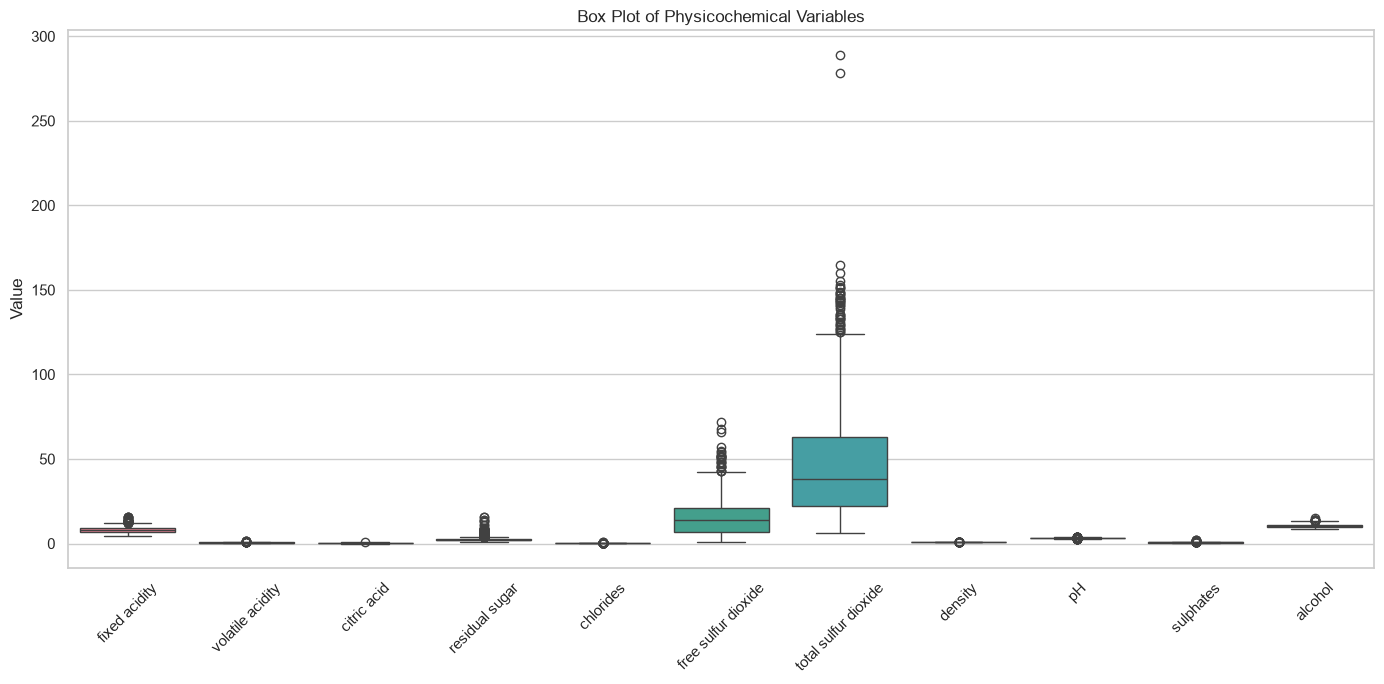

In [59]:
plt.figure(figsize=(14, 7))

sns.boxplot(data=df_clean[features])

plt.title("Box Plot of Physicochemical Variables")
plt.xticks(rotation=45)
plt.ylabel("Value")

plt.tight_layout()
plt.show()

1, Duplicate impact

In [60]:
print("Original dataset size:", len(df))
print("Duplicate rows:", df.duplicated().sum())
print("Unique rows:", df.drop_duplicates().shape[0])

df_clean = df.drop_duplicates().copy()

print("\nOriginal mean quality:", df["quality"].mean())
print("Cleaned mean quality:", df_clean["quality"].mean())

print("\nOriginal mean alcohol:", df["alcohol"].mean())
print("Cleaned mean alcohol:", df_clean["alcohol"].mean())

Original dataset size: 1599
Duplicate rows: 240
Unique rows: 1359

Original mean quality: 5.6360225140712945
Cleaned mean quality: 5.6232523914643116

Original mean alcohol: 10.422983114446529
Cleaned mean alcohol: 10.432315428010792


2. Quality Distribution

In [61]:
print(df_clean["quality"].value_counts().sort_index())

quality
3     10
4     53
5    577
6    535
7    167
8     17
Name: count, dtype: int64


3. Full Desciptive Statistics

In [62]:
features = [
    "fixed acidity",
    "volatile acidity",
    "citric acid",
    "residual sugar",
    "chlorides",
    "free sulfur dioxide",
    "total sulfur dioxide",
    "density",
    "pH",
    "sulphates",
    "alcohol"
]

stats_table = pd.DataFrame({
    "Mean": df_clean[features].mean(),
    "Median": df_clean[features].median(),
    "Variance": df_clean[features].var(),
    "Std Dev": df_clean[features].std(),
    "Minimum": df_clean[features].min(),
    "Maximum": df_clean[features].max(),
    "Range": df_clean[features].max() - df_clean[features].min(),
    "Q1": df_clean[features].quantile(0.25),
    "Q3": df_clean[features].quantile(0.75),
    "IQR": df_clean[features].quantile(0.75) -
           df_clean[features].quantile(0.25),
    "Skewness": df_clean[features].skew(),
    "Kurtosis": df_clean[features].kurt()
})

stats_table

,Mean,Median,Variance,Std Dev,Minimum,Maximum,Range,Q1,Q3,IQR,Skewness,Kurtosis
fixed acidity,8.3106,7.9000,3.0171,1.7370,4.6000,15.9000,11.3000,7.1000,9.2000,2.1000,0.9410,1.0497
volatile acidity,0.5295,0.5200,0.0335,0.1830,0.1200,1.5800,1.4600,0.3900,0.6400,0.2500,0.7293,1.2492
citric acid,0.2723,0.2600,0.0382,0.1955,0.0000,1.0000,1.0000,0.0900,0.4300,0.3400,0.3127,-0.7889
residual sugar,2.5234,2.2000,1.8288,1.3523,0.9000,15.5000,14.6000,1.9000,2.6000,0.7000,4.5482,29.3646
chlorides,0.0881,0.0790,0.0024,0.0494,0.0120,0.6110,0.5990,0.0700,0.0910,0.0210,5.5025,38.6247
free sulfur dioxide,15.8933,14.0000,109.1455,10.4473,1.0000,72.0000,71.0000,7.0000,21.0000,14.0000,1.2266,1.8927
total sulfur dioxide,46.8260,38.0000,1116.1577,33.4089,6.0000,289.0000,283.0000,22.0000,63.0000,41.0000,1.5404,4.0423
density,0.9967,0.9967,0.0000,0.0019,0.9901,1.0037,0.0136,0.9956,0.9978,0.0022,0.0448,0.8307
pH,3.3098,3.3100,0.0240,0.1550,2.7400,4.0100,1.2700,3.2100,3.4000,0.1900,0.2320,0.8798
sulphates,0.6587,0.6200,0.0291,0.1707,0.3300,2.0000,1.6700,0.5500,0.7300,0.1800,2.4065,11.1023


Lock our cleaned dataset

In [63]:
print("Final dataset shape:", df_clean.shape)

Final dataset shape: (1359, 12)


Create a proper descriptive-statistics table

In [64]:
descriptive_stats = pd.DataFrame({
    "Mean": df_clean[features].mean(),
    "Median": df_clean[features].median(),
    "Variance": df_clean[features].var(),
    "Std Dev": df_clean[features].std(),
    "Minimum": df_clean[features].min(),
    "Q1": df_clean[features].quantile(0.25),
    "Q3": df_clean[features].quantile(0.75),
    "Maximum": df_clean[features].max(),
    "IQR": df_clean[features].quantile(0.75) - df_clean[features].quantile(0.25),
    "Skewness": df_clean[features].skew(),
    "Kurtosis": df_clean[features].kurt(),
})

descriptive_stats["CV (%)"] = (
    descriptive_stats["Std Dev"] /
    descriptive_stats["Mean"]
) * 100

descriptive_stats.round(4)

,Mean,Median,Variance,Std Dev,Minimum,Q1,Q3,Maximum,IQR,Skewness,Kurtosis,CV (%)
fixed acidity,8.3106,7.9000,3.0171,1.7370,4.6000,7.1000,9.2000,15.9000,2.1000,0.9410,1.0497,20.9009
volatile acidity,0.5295,0.5200,0.0335,0.1830,0.1200,0.3900,0.6400,1.5800,0.2500,0.7293,1.2492,34.5683
citric acid,0.2723,0.2600,0.0382,0.1955,0.0000,0.0900,0.4300,1.0000,0.3400,0.3127,-0.7889,71.8006
residual sugar,2.5234,2.2000,1.8288,1.3523,0.9000,1.9000,2.6000,15.5000,0.7000,4.5482,29.3646,53.5909
chlorides,0.0881,0.0790,0.0024,0.0494,0.0120,0.0700,0.0910,0.6110,0.0210,5.5025,38.6247,56.0314
free sulfur dioxide,15.8933,14.0000,109.1455,10.4473,1.0000,7.0000,21.0000,72.0000,14.0000,1.2266,1.8927,65.7338
total sulfur dioxide,46.8260,38.0000,1116.1577,33.4089,6.0000,22.0000,63.0000,289.0000,41.0000,1.5404,4.0423,71.3470
density,0.9967,0.9967,0.0000,0.0019,0.9901,0.9956,0.9978,1.0037,0.0022,0.0448,0.8307,0.1875
pH,3.3098,3.3100,0.0240,0.1550,2.7400,3.2100,3.4000,4.0100,0.1900,0.2320,0.8798,4.6842
sulphates,0.6587,0.6200,0.0291,0.1707,0.3300,0.5500,0.7300,2.0000,0.1800,2.4065,11.1023,25.9095


Now let's do our first confidence interval on alcohol

In [65]:
alcohol = df_clean["alcohol"]

n = len(alcohol)
mean = alcohol.mean()
std = alcohol.std(ddof=1)

confidence = 0.95
alpha = 1 - confidence

t_critical = stats.t.ppf(1 - alpha / 2, df=n - 1)

margin_error = t_critical * (std / np.sqrt(n))

lower = mean - margin_error
upper = mean + margin_error

print("Sample size:", n)
print("Sample mean:", mean)
print("Standard deviation:", std)
print("t-critical:", t_critical)
print("Margin of error:", margin_error)
print("95% Confidence Interval:", (lower, upper))

Sample size: 1359
Sample mean: 10.432315428010792
Standard deviation: 1.0820654499402542
t-critical: 1.961712402095267
Margin of error: 0.05758099161935269
95% Confidence Interval: (np.float64(10.374734436391439), np.float64(10.489896419630146))


First hypothesis test

In [66]:
sample_mean = df_clean["alcohol"].mean()

t_stat, p_value = stats.ttest_1samp(
    df_clean["alcohol"],
    popmean=10
)

alpha = 0.05

print("Hypothesized population mean:", 10)
print("Sample mean:", sample_mean)
print("t-statistic:", t_stat)
print("p-value:", p_value)

if p_value < alpha:
    print("Decision: Reject H0")
else:
    print("Decision: Fail to reject H0")

Hypothesized population mean: 10
Sample mean: 10.432315428010792
t-statistic: 14.7284461919697
p-value: 1.156101460255053e-45
Decision: Reject H0


Our sample-size experiment

In [67]:
sample_sizes = [50, 100, 250, 500, 1000]

results = []

for n in sample_sizes:
    sample = df_clean["alcohol"].sample(
        n=n,
        random_state=42
    )

    mean = sample.mean()
    variance = sample.var()
    std = sample.std()

    t_critical = stats.t.ppf(
        0.975,
        df=n-1
    )

    margin_error = t_critical * std / np.sqrt(n)

    ci_lower = mean - margin_error
    ci_upper = mean + margin_error

    t_stat, p_value = stats.ttest_1samp(
        sample,
        popmean=10
    )

    results.append({
        "Sample Size": n,
        "Mean": mean,
        "Variance": variance,
        "Std Dev": std,
        "CI Lower": ci_lower,
        "CI Upper": ci_upper,
        "CI Width": ci_upper - ci_lower,
        "t-statistic": t_stat,
        "p-value": p_value
    })

sample_size_results = pd.DataFrame(results)

sample_size_results

,Sample Size,Mean,Variance,Std Dev,CI Lower,CI Upper,CI Width,t-statistic,p-value
0,50,10.3480,1.0336,1.0166,10.0591,10.6369,0.5779,2.4204,0.0193
1,100,10.3750,1.0748,1.0367,10.1693,10.5807,0.4114,3.6171,0.0005
2,250,10.4234,1.0872,1.0427,10.2935,10.5533,0.2598,6.4205,0.0000
3,500,10.4818,1.1798,1.0862,10.3864,10.5773,0.1909,9.9192,0.0000
4,1000,10.4334,1.1584,1.0763,10.3666,10.5002,0.1336,12.7338,0.0000


Visualize sample-size effect

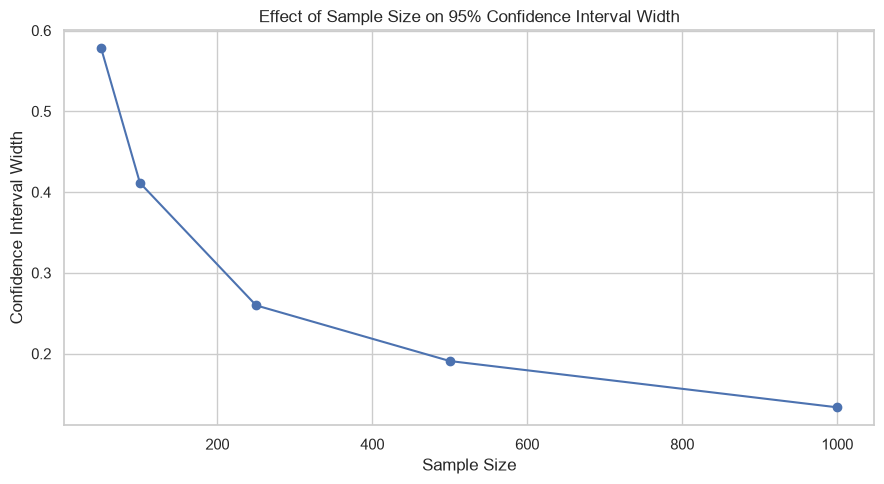

In [68]:
plt.figure(figsize=(9, 5))

plt.plot(
    sample_size_results["Sample Size"],
    sample_size_results["CI Width"],
    marker="o"
)

plt.title("Effect of Sample Size on 95% Confidence Interval Width")
plt.xlabel("Sample Size")
plt.ylabel("Confidence Interval Width")

plt.tight_layout()
plt.show()

## Comparative Statistical Analysis

Create Low-Quality and High-Quality Groups

In [69]:
low_quality = df_clean[df_clean["quality"] <= 5]
high_quality = df_clean[df_clean["quality"] >= 6]

print("Low-quality wines:", len(low_quality))
print("High-quality wines:", len(high_quality))

Low-quality wines: 640
High-quality wines: 719


In [70]:
comparison = pd.DataFrame({
    "Low Quality": low_quality["alcohol"].describe(),
    "High Quality": high_quality["alcohol"].describe()
})

comparison

,Low Quality,High Quality
count,640.0000,719.0000
mean,9.9208,10.8876
std,0.7735,1.1141
min,8.4000,8.4000
25%,9.4000,10.0000
50%,9.7000,10.8000
75%,10.3000,11.7000
max,14.9000,14.0000


In [71]:
print("Low-quality mean alcohol:",
      low_quality["alcohol"].mean())

print("High-quality mean alcohol:",
      high_quality["alcohol"].mean())

print("Low-quality SD:",
      low_quality["alcohol"].std())

print("High-quality SD:",
      high_quality["alcohol"].std())

Low-quality mean alcohol: 9.920781250000001
High-quality mean alcohol: 10.887644877144183
Low-quality SD: 0.7734782215888825
High-quality SD: 1.1141082478181112


Visualize the two groups

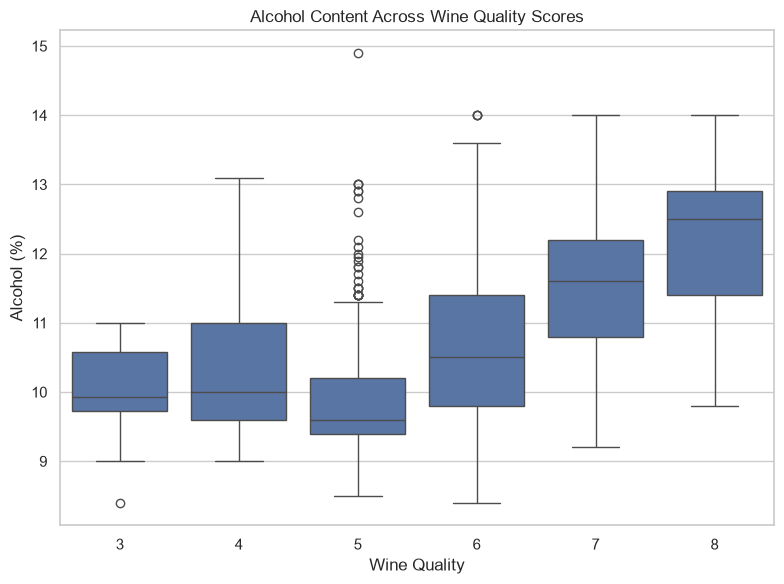

In [72]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df_clean,
    x="quality",
    y="alcohol"
)

plt.title("Alcohol Content Across Wine Quality Scores")
plt.xlabel("Wine Quality")
plt.ylabel("Alcohol (%)")

plt.tight_layout()
plt.show()

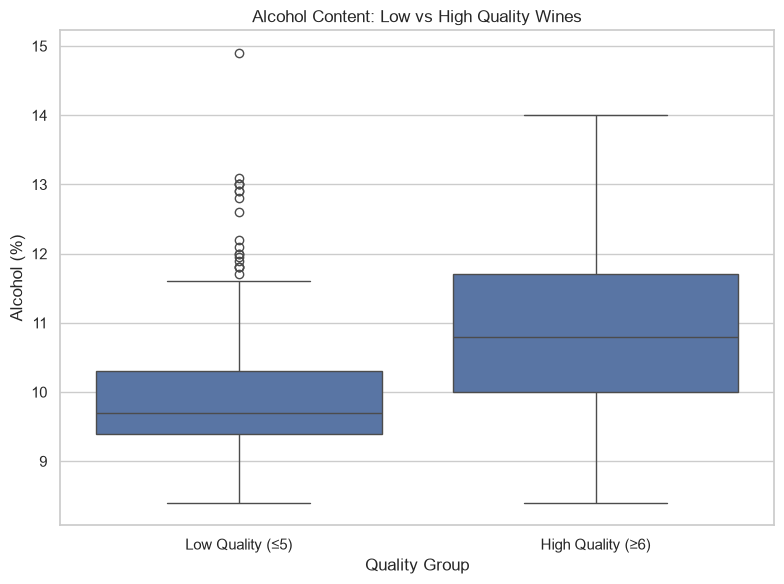

In [73]:
plot_data = df_clean.copy()

plot_data["Quality Group"] = np.where(
    plot_data["quality"] <= 5,
    "Low Quality (≤5)",
    "High Quality (≥6)"
)

plt.figure(figsize=(8, 6))

sns.boxplot(
    data=plot_data,
    x="Quality Group",
    y="alcohol"
)

plt.title("Alcohol Content: Low vs High Quality Wines")
plt.xlabel("Quality Group")
plt.ylabel("Alcohol (%)")

plt.tight_layout()
plt.show()

Independent Two-Sample t-Test

In [74]:
low_alcohol = low_quality["alcohol"]
high_alcohol = high_quality["alcohol"]

t_stat, p_value = stats.ttest_ind(
    low_alcohol,
    high_alcohol,
    equal_var=False
)

print("Low-quality mean:", low_alcohol.mean())
print("High-quality mean:", high_alcohol.mean())
print("t-statistic:", t_stat)
print("p-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("Decision: Reject H0")
else:
    print("Decision: Fail to reject H0")

Low-quality mean: 9.920781250000001
High-quality mean: 10.887644877144183
t-statistic: -18.742690953986735
p-value: 1.8012380348945453e-69
Decision: Reject H0


95% Confidence Interval for Difference in Means

In [75]:
mean_low = low_alcohol.mean()
mean_high = high_alcohol.mean()

var_low = low_alcohol.var()
var_high = high_alcohol.var()

n_low = len(low_alcohol)
n_high = len(high_alcohol)

mean_diff = mean_high - mean_low

se_diff = np.sqrt(
    var_low / n_low +
    var_high / n_high
)

df_welch = (
    (var_low / n_low + var_high / n_high) ** 2
    /
    (
        (var_low / n_low) ** 2 / (n_low - 1)
        +
        (var_high / n_high) ** 2 / (n_high - 1)
    )
)

t_critical = stats.t.ppf(
    0.975,
    df_welch
)

margin_error = t_critical * se_diff

ci_lower = mean_diff - margin_error
ci_upper = mean_diff + margin_error

print("Difference in means:", mean_diff)
print("95% CI:", (ci_lower, ci_upper))
print("Degrees of freedom:", df_welch)

Difference in means: 0.966863627144182
95% CI: (np.float64(0.8656611446293907), np.float64(1.0680661096589732))
Degrees of freedom: 1283.3057130545633


# Correlation Analysis

Pearson's correlation coefficient**

In [76]:
r, p_value = stats.pearsonr(
    df_clean["alcohol"],
    df_clean["quality"]
)

print("Pearson correlation coefficient:", r)
print("p-value:", p_value)

Pearson correlation coefficient: 0.4803428980019916
p-value: 2.2787211325406987e-79


In [77]:
if p_value < 0.05:
    print("Decision: Reject H0")
    print("There is a statistically significant linear relationship.")
else:
    print("Decision: Fail to reject H0")
    print("There is insufficient evidence of a significant linear relationship.")

Decision: Reject H0
There is a statistically significant linear relationship.


Scatter Plot

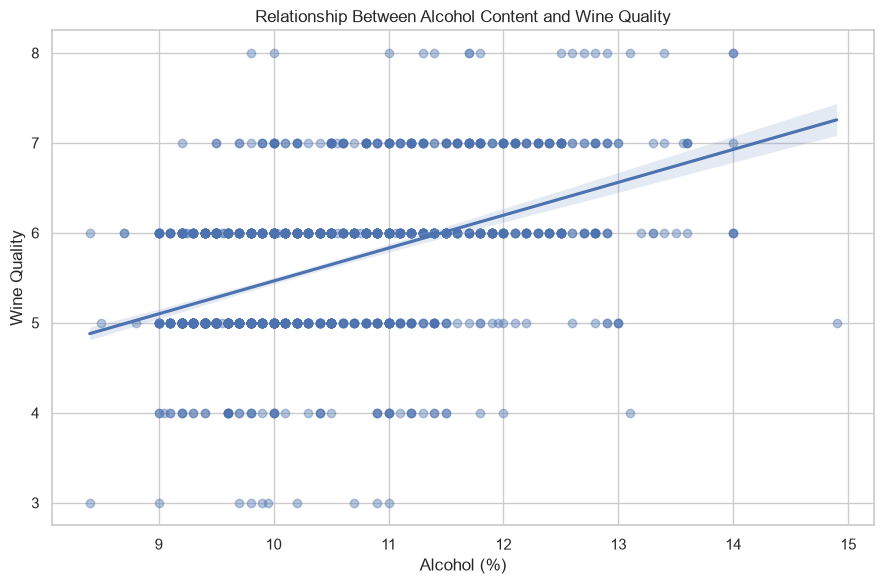

In [78]:
plt.figure(figsize=(9, 6))

sns.regplot(
    data=df_clean,
    x="alcohol",
    y="quality",
    scatter_kws={"alpha": 0.4},
    line_kws={}
)

plt.title("Relationship Between Alcohol Content and Wine Quality")
plt.xlabel("Alcohol (%)")
plt.ylabel("Wine Quality")

plt.tight_layout()
plt.show()

Correlation Heatmap

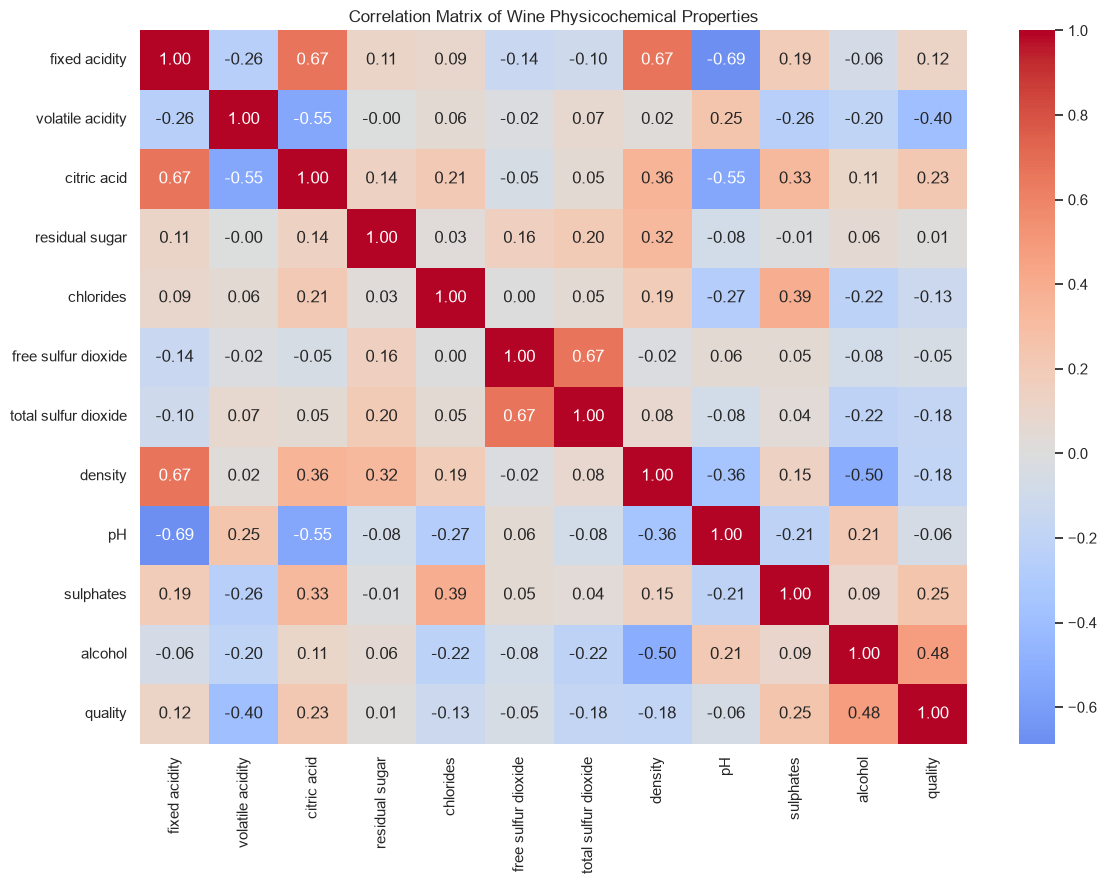

In [79]:
correlation_matrix = df_clean.corr(numeric_only=True)

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Wine Physicochemical Properties")

plt.tight_layout()
plt.show()

# Machine Learning Analysis — K-Fold Cross-Validation

Prepare X and y

In [80]:
X = df_clean[features]
y = df_clean["quality"]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

Feature matrix shape: (1359, 11)
Target shape: (1359,)


Create 5-fold cross-validation

In [81]:
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Number of folds:", kf.get_n_splits())

Number of folds: 5


Linear Regression

In [83]:
linear_model = LinearRegression()

In [85]:
linear_results = []

for fold, (train_index, test_index) in enumerate(kf.split(X), start=1):

    X_train = X.iloc[train_index]
    X_test = X.iloc[test_index]

    y_train = y.iloc[train_index]
    y_test = y.iloc[test_index]

    linear_model.fit(X_train, y_train)

    y_pred = linear_model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    linear_results.append({
        "Fold": fold,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R²": r2
    })

linear_results_df = pd.DataFrame(linear_results)

linear_results_df

,Fold,MAE,MSE,RMSE,R²
0,1,0.5041,0.4310,0.6565,0.3915
1,2,0.4928,0.4236,0.6508,0.3423
2,3,0.5213,0.4474,0.6689,0.3535
3,4,0.5346,0.4622,0.6798,0.3139
4,5,0.5062,0.4444,0.6667,0.3312


Calculate average performance

In [86]:
linear_summary = pd.DataFrame({
    "Mean": linear_results_df.drop(columns="Fold").mean(),
    "Std Dev": linear_results_df.drop(columns="Fold").std()
})

linear_summary

,Mean,Std Dev
MAE,0.5118,0.0163
MSE,0.4417,0.0150
RMSE,0.6645,0.0113
R²,0.3465,0.0291


Random Forest Regression

In [87]:
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

In [88]:
rf_results = []

for fold, (train_index, test_index) in enumerate(kf.split(X), start=1):

    X_train = X.iloc[train_index]
    X_test = X.iloc[test_index]

    y_train = y.iloc[train_index]
    y_test = y.iloc[test_index]

    rf_model.fit(X_train, y_train)

    y_pred = rf_model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    rf_results.append({
        "Fold": fold,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R²": r2
    })

rf_results_df = pd.DataFrame(rf_results)

rf_results_df

,Fold,MAE,MSE,RMSE,R²
0,1,0.4699,0.3816,0.6178,0.4613
1,2,0.4873,0.4131,0.6428,0.3585
2,3,0.4909,0.4110,0.6411,0.4061
3,4,0.5067,0.4288,0.6548,0.3634
4,5,0.5106,0.4406,0.6638,0.3370


Compare the two models

In [89]:
model_comparison = pd.DataFrame({
    "Linear Regression": linear_results_df[
        ["MAE", "MSE", "RMSE", "R²"]
    ].mean(),

    "Random Forest": rf_results_df[
        ["MAE", "MSE", "RMSE", "R²"]
    ].mean()
})

model_comparison

,Linear Regression,Random Forest
MAE,0.5118,0.4931
MSE,0.4417,0.4150
RMSE,0.6645,0.6440
R²,0.3465,0.3853


Visualize the model comparison

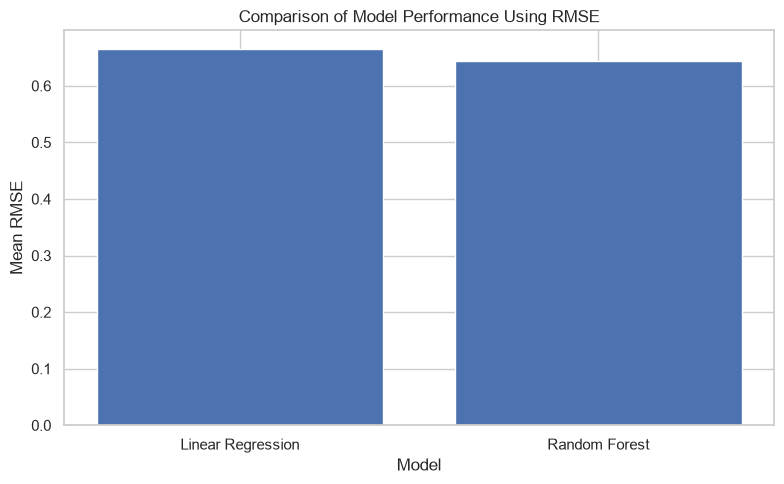

In [90]:
model_names = ["Linear Regression", "Random Forest"]

rmse_values = [
    linear_results_df["RMSE"].mean(),
    rf_results_df["RMSE"].mean()
]

plt.figure(figsize=(8, 5))

plt.bar(
    model_names,
    rmse_values
)

plt.title("Comparison of Model Performance Using RMSE")
plt.xlabel("Model")
plt.ylabel("Mean RMSE")

plt.tight_layout()
plt.show()

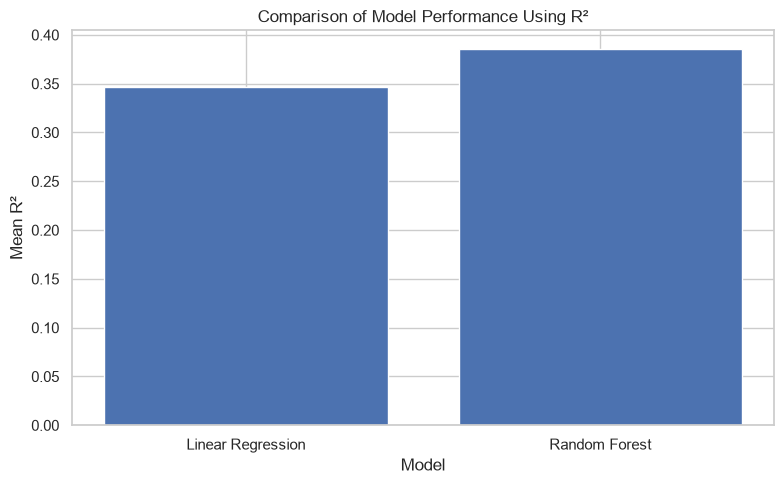

In [91]:
r2_values = [
    linear_results_df["R²"].mean(),
    rf_results_df["R²"].mean()
]

plt.figure(figsize=(8, 5))

plt.bar(
    model_names,
    r2_values
)

plt.title("Comparison of Model Performance Using R²")
plt.xlabel("Model")
plt.ylabel("Mean R²")

plt.tight_layout()
plt.show()

Feature importance — Random Forest

In [92]:
rf_final = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_final.fit(X, y)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

In [93]:
feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": rf_final.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

feature_importance

,Feature,Importance
10,alcohol,0.2777
9,sulphates,0.1392
1,volatile acidity,0.1295
6,total sulfur dioxide,0.0770
4,chlorides,0.0623
3,residual sugar,0.0583
8,pH,0.0578
7,density,0.0520
0,fixed acidity,0.0506
2,citric acid,0.0483


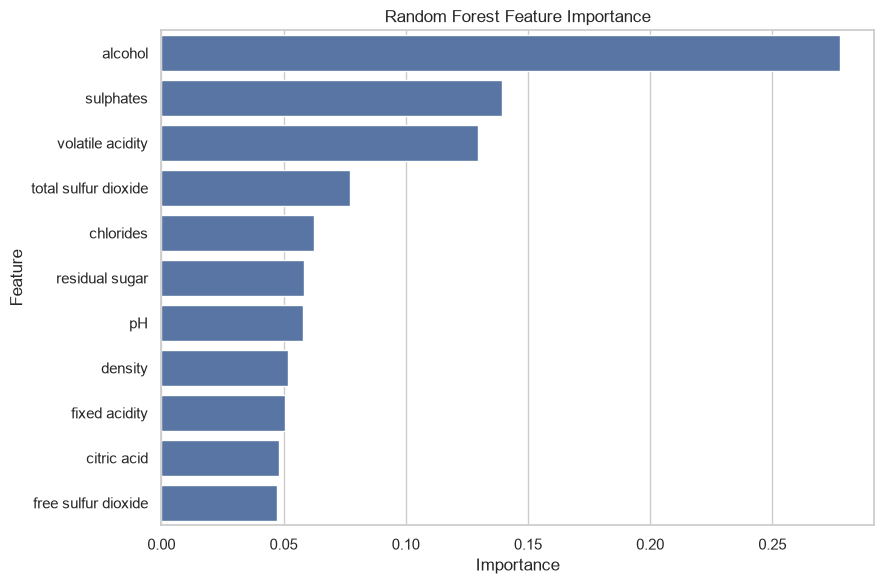

In [94]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

# Repeated Sample-Size Experiment

The experimental design

Run the repeated experiment

In [95]:
sample_sizes = [50, 100, 250, 500, 1000]
n_repetitions = 30

reference_mean = df_clean["alcohol"].mean()

repeated_results = []

for n in sample_sizes:

    for repetition in range(n_repetitions):

        sample = df_clean["alcohol"].sample(
            n=n,
            random_state=1000 + repetition + n
        )

        sample_mean = sample.mean()
        sample_variance = sample.var()
        sample_std = sample.std()

        t_critical = stats.t.ppf(
            0.975,
            df=n - 1
        )

        margin_error = (
            t_critical *
            sample_std /
            np.sqrt(n)
        )

        ci_lower = sample_mean - margin_error
        ci_upper = sample_mean + margin_error

        t_stat, p_value = stats.ttest_1samp(
            sample,
            popmean=10
        )

        ci_contains_reference = (
            ci_lower <= reference_mean <= ci_upper
        )

        repeated_results.append({
            "Sample Size": n,
            "Repetition": repetition + 1,
            "Mean": sample_mean,
            "Variance": sample_variance,
            "Std Dev": sample_std,
            "CI Lower": ci_lower,
            "CI Upper": ci_upper,
            "CI Width": ci_upper - ci_lower,
            "t-statistic": t_stat,
            "p-value": p_value,
            "CI Contains Reference Mean": ci_contains_reference,
            "Reject H0": p_value < 0.05
        })

repeated_results_df = pd.DataFrame(repeated_results)

repeated_results_df.head()

,Sample Size,Repetition,Mean,Variance,Std Dev,CI Lower,CI Upper,CI Width,t-statistic,p-value,CI Contains Reference Mean,Reject H0
0,50,1,10.4590,1.0200,1.0099,10.1720,10.7460,0.5740,3.2137,0.0023,True,True
1,50,2,10.5380,1.0730,1.0359,10.2436,10.8324,0.5888,3.6725,0.0006,True,True
2,50,3,10.4240,1.0819,1.0401,10.1284,10.7196,0.5912,2.8825,0.0058,True,True
3,50,4,10.3980,1.0700,1.0344,10.1040,10.6920,0.5879,2.7207,0.0090,True,True
4,50,5,10.4350,1.5202,1.2330,10.0846,10.7854,0.7008,2.4947,0.0160,True,True


In [96]:
print("Total experiments:", len(repeated_results_df))

Total experiments: 150


Summarize the results

In [97]:
repeated_summary = repeated_results_df.groupby(
    "Sample Size"
).agg({
    "Mean": ["mean", "std"],
    "Variance": ["mean", "std"],
    "Std Dev": ["mean", "std"],
    "CI Width": ["mean", "std"],
    "CI Contains Reference Mean": "mean",
    "Reject H0": "mean"
})

repeated_summary

Mean        Variance        Std Dev        CI Width         \
               mean    std     mean    std    mean    std     mean    std   
Sample Size                                                                 
50          10.4453 0.1626   1.2037 0.2504  1.0917 0.1111   0.6205 0.0631   
100         10.4221 0.1137   1.1120 0.1354  1.0525 0.0656   0.4177 0.0260   
250         10.4404 0.0691   1.1722 0.0945  1.0819 0.0434   0.2695 0.0108   
500         10.4201 0.0445   1.1608 0.0554  1.0771 0.0255   0.1893 0.0045   
1000        10.4325 0.0160   1.1660 0.0315  1.0797 0.0146   0.1340 0.0018   

            CI Contains Reference Mean Reject H0  
                                  mean      mean  
Sample Size                                       
50                              0.9667    0.8333  
100                             0.9333    1.0000  
250                             0.9333    1.0000  
500                             0.9667    1.0000  
1000                            1.0000    1.0000

Make the table easier to read

In [98]:
summary_table = repeated_results_df.groupby(
    "Sample Size"
).agg(
    Mean=("Mean", "mean"),
    Mean_SD=("Mean", "std"),
    Variance=("Variance", "mean"),
    Std_Dev=("Std Dev", "mean"),
    Avg_CI_Width=("CI Width", "mean"),
    CI_Coverage=("CI Contains Reference Mean", "mean"),
    H0_Rejection_Rate=("Reject H0", "mean")
).reset_index()

summary_table["CI_Coverage"] *= 100
summary_table["H0_Rejection_Rate"] *= 100

summary_table.round(4)

,Sample Size,Mean,Mean_SD,Variance,Std_Dev,Avg_CI_Width,CI_Coverage,H0_Rejection_Rate
0,50,10.4453,0.1626,1.2037,1.0917,0.6205,96.6667,83.3333
1,100,10.4221,0.1137,1.1120,1.0525,0.4177,93.3333,100.0000
2,250,10.4404,0.0691,1.1722,1.0819,0.2695,93.3333,100.0000
3,500,10.4201,0.0445,1.1608,1.0771,0.1893,96.6667,100.0000
4,1000,10.4325,0.0160,1.1660,1.0797,0.1340,100.0000,100.0000


Graph — Sample Size vs Average CI Width

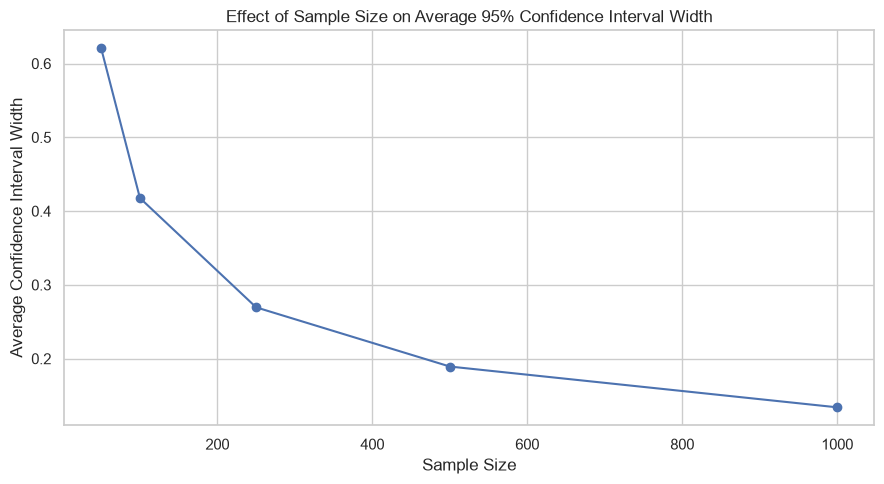

In [99]:
plt.figure(figsize=(9, 5))

plt.plot(
    summary_table["Sample Size"],
    summary_table["Avg_CI_Width"],
    marker="o"
)

plt.title("Effect of Sample Size on Average 95% Confidence Interval Width")
plt.xlabel("Sample Size")
plt.ylabel("Average Confidence Interval Width")

plt.tight_layout()
plt.show()

Graph — Sample Size vs CI Coverage

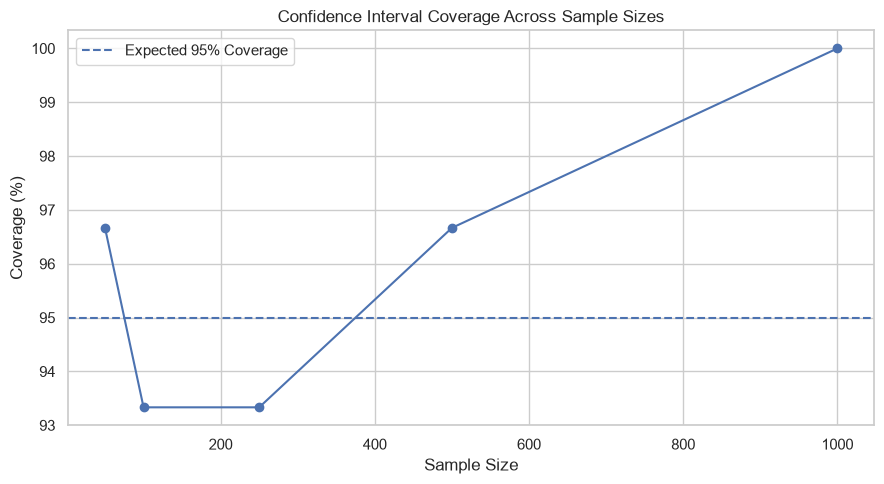

In [100]:
plt.figure(figsize=(9, 5))

plt.plot(
    summary_table["Sample Size"],
    summary_table["CI_Coverage"],
    marker="o"
)

plt.axhline(
    95,
    linestyle="--",
    label="Expected 95% Coverage"
)

plt.title("Confidence Interval Coverage Across Sample Sizes")
plt.xlabel("Sample Size")
plt.ylabel("Coverage (%)")

plt.legend()

plt.tight_layout()
plt.show()

Graph — Sample Size vs Mean Estimate

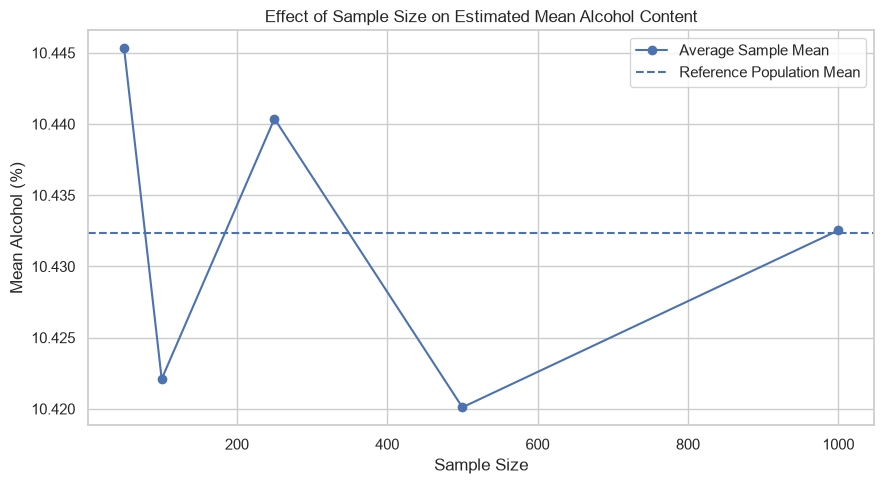

In [101]:
plt.figure(figsize=(9, 5))

plt.plot(
    summary_table["Sample Size"],
    summary_table["Mean"],
    marker="o",
    label="Average Sample Mean"
)

plt.axhline(
    reference_mean,
    linestyle="--",
    label="Reference Population Mean"
)

plt.title("Effect of Sample Size on Estimated Mean Alcohol Content")
plt.xlabel("Sample Size")
plt.ylabel("Mean Alcohol (%)")

plt.legend()

plt.tight_layout()
plt.show()

Graph — Hypothesis-Test Rejection Rate

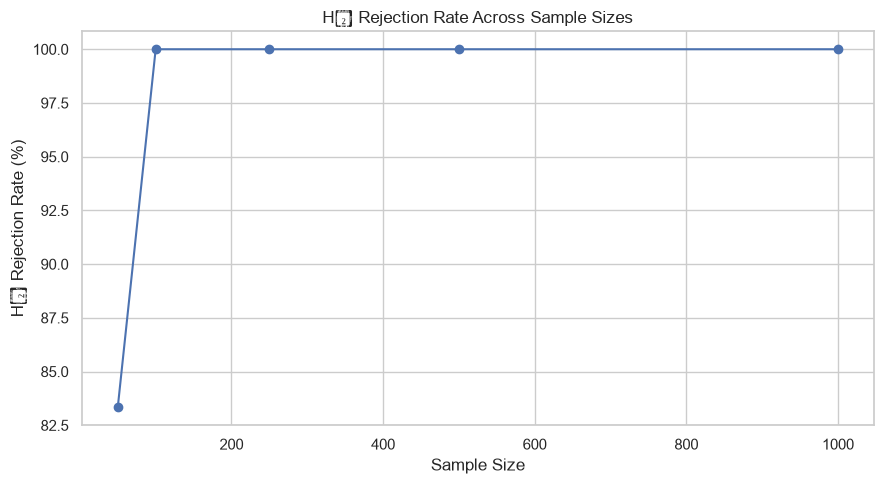

In [102]:
plt.figure(figsize=(9, 5))

plt.plot(
    summary_table["Sample Size"],
    summary_table["H0_Rejection_Rate"],
    marker="o"
)

plt.title("H₀ Rejection Rate Across Sample Sizes")
plt.xlabel("Sample Size")
plt.ylabel("H₀ Rejection Rate (%)")

plt.tight_layout()
plt.show()

# Export Final Graphs and Tables

9. Final Graphs and Statistical Results

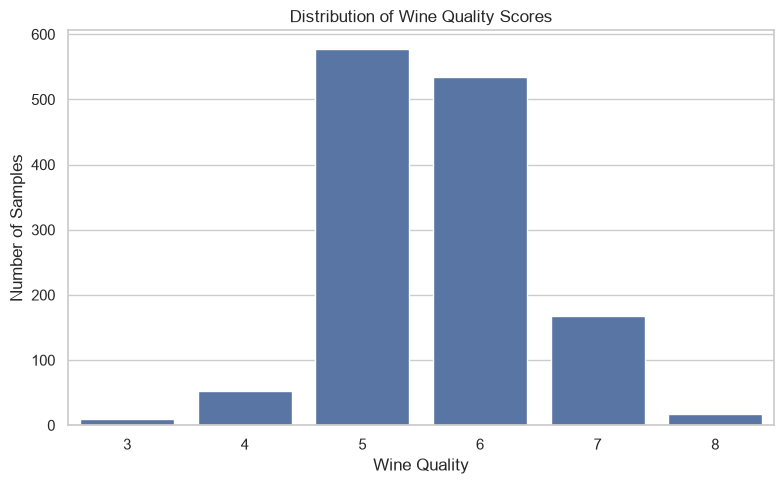

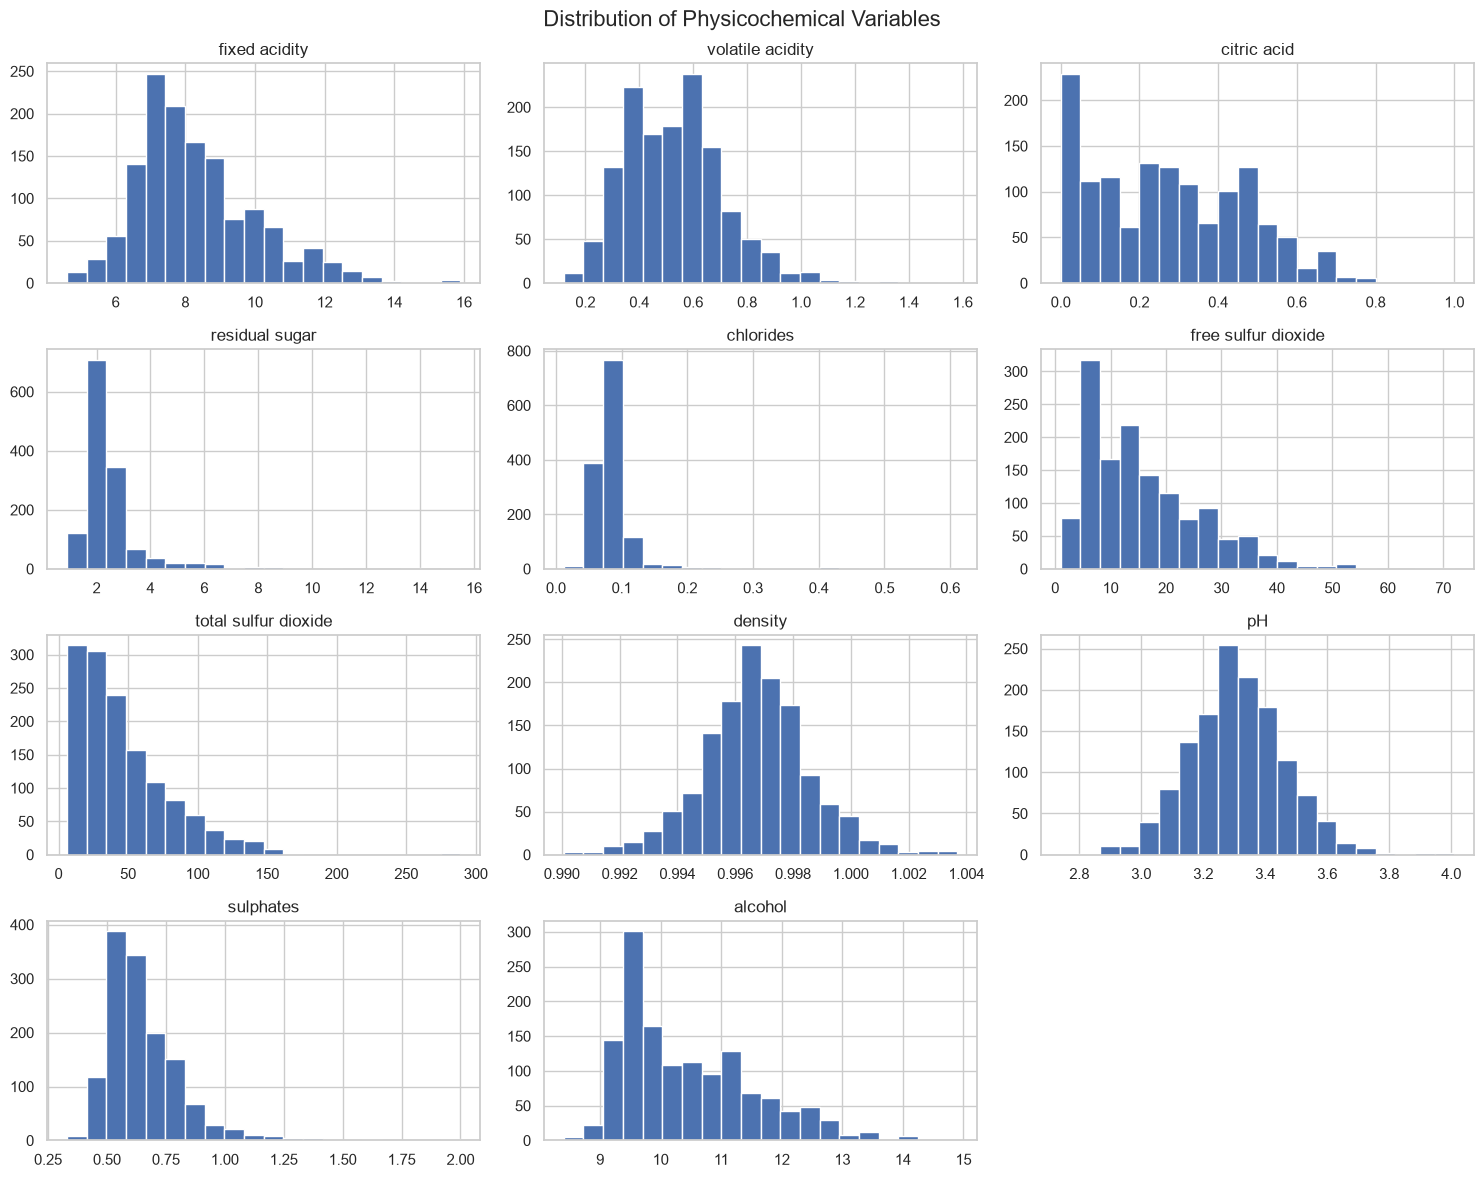

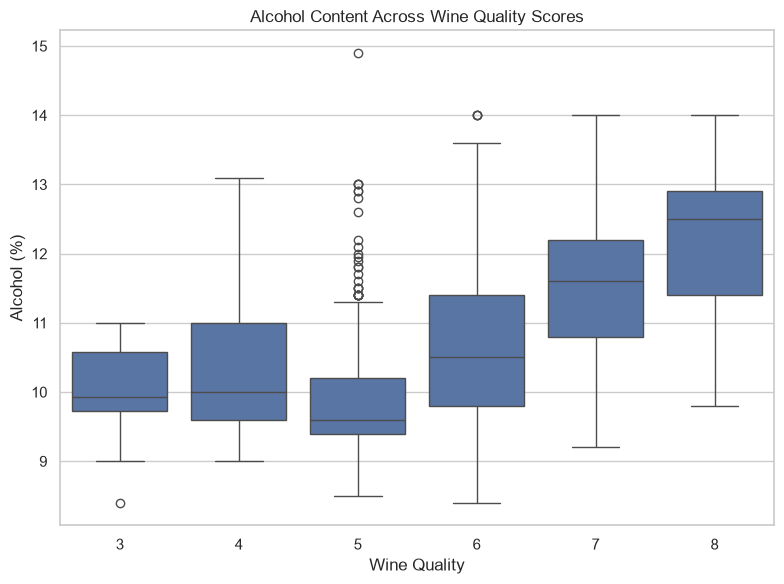

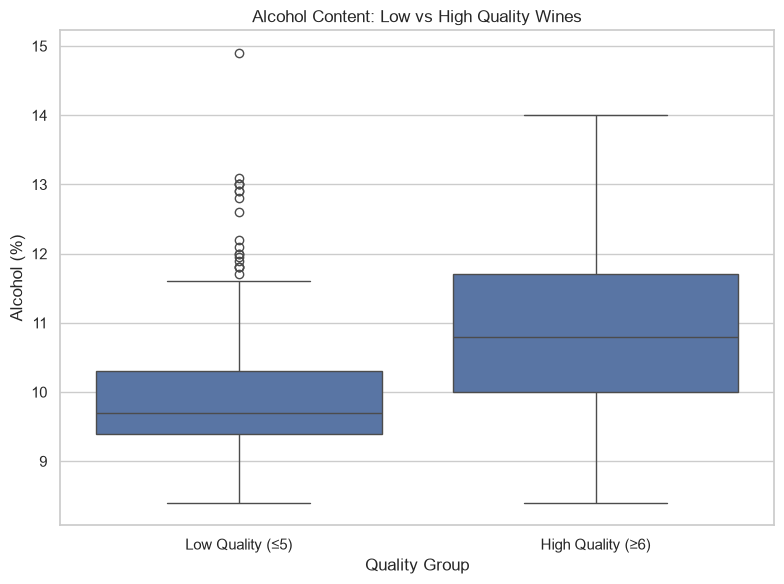

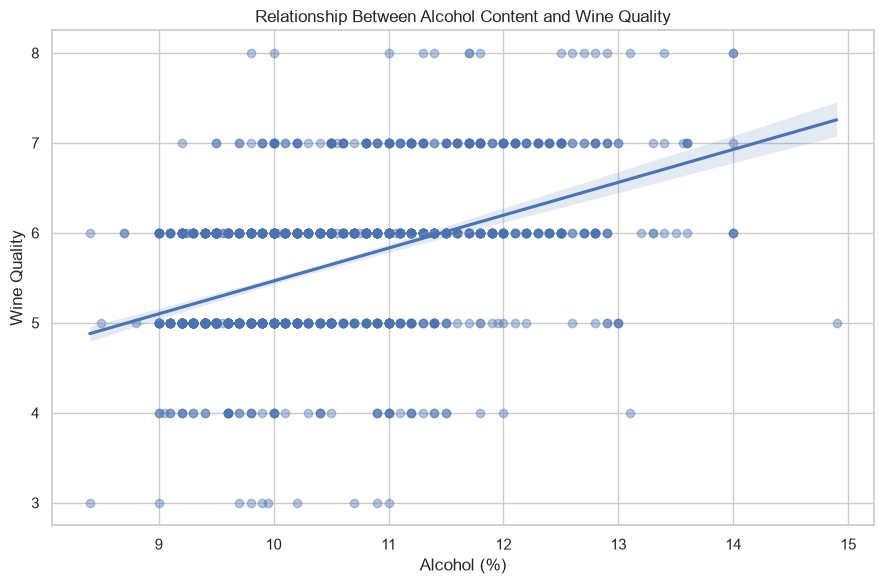

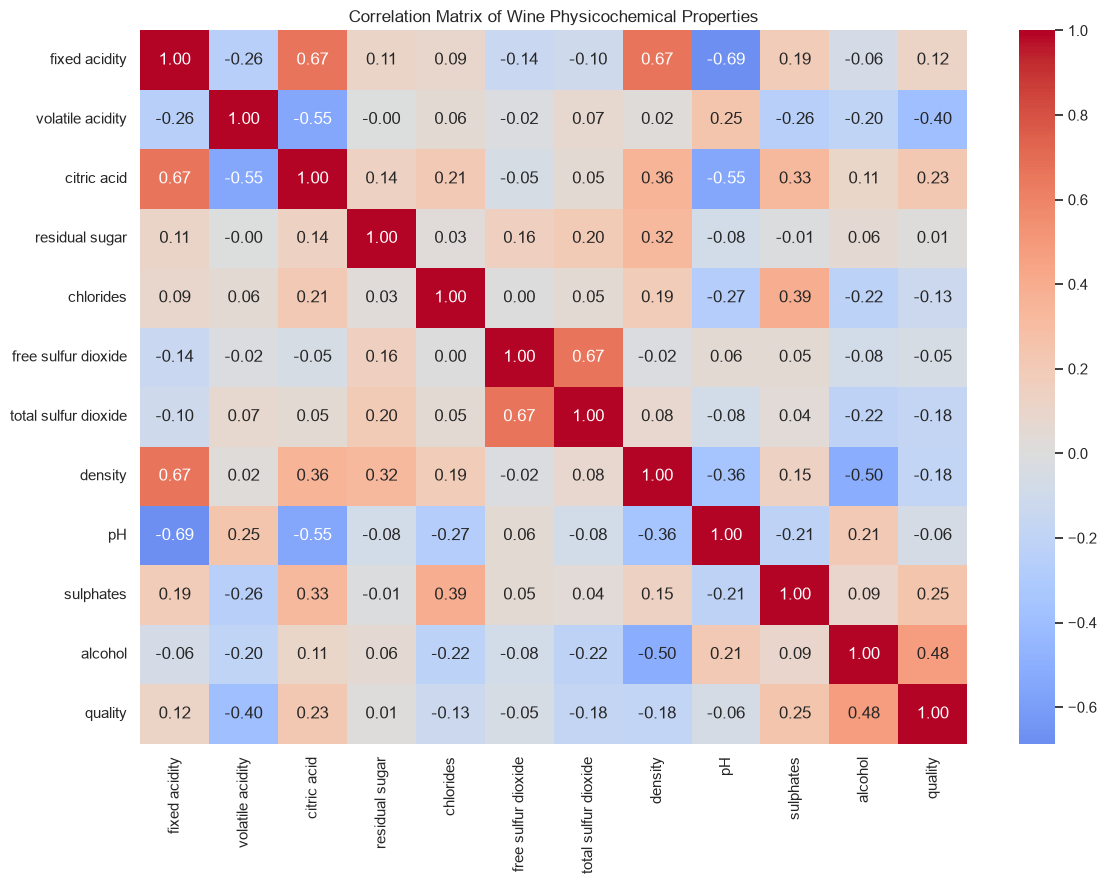

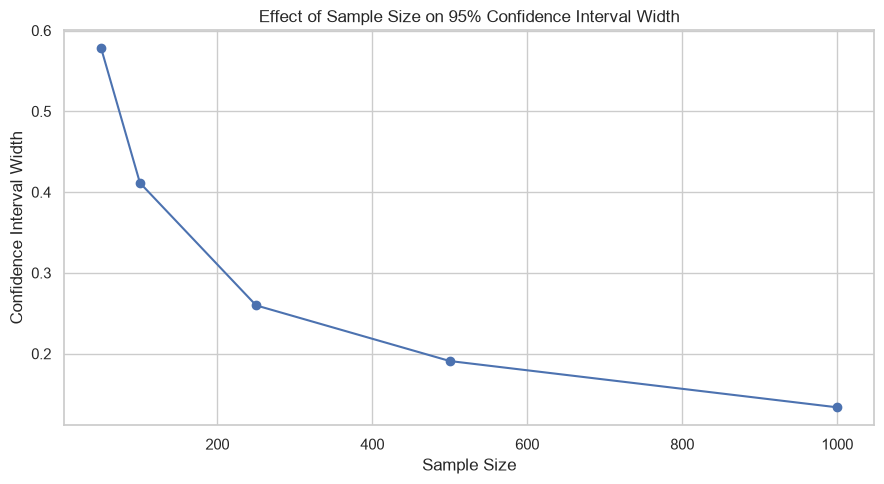

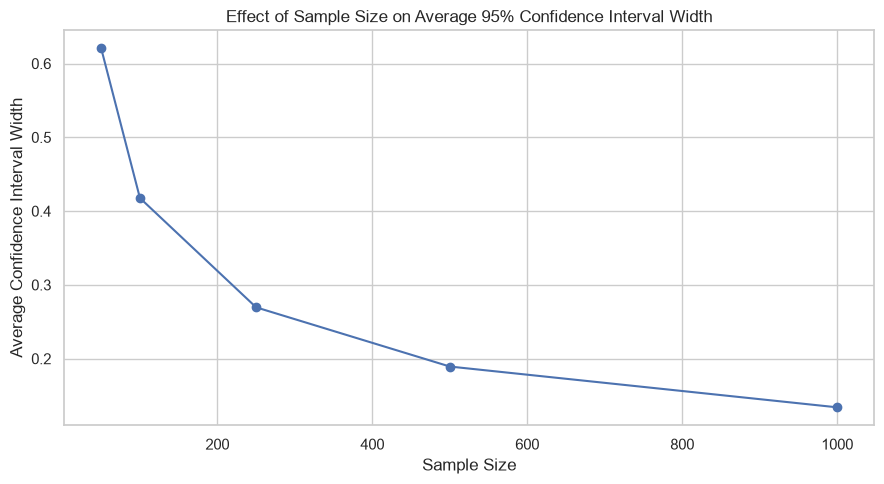

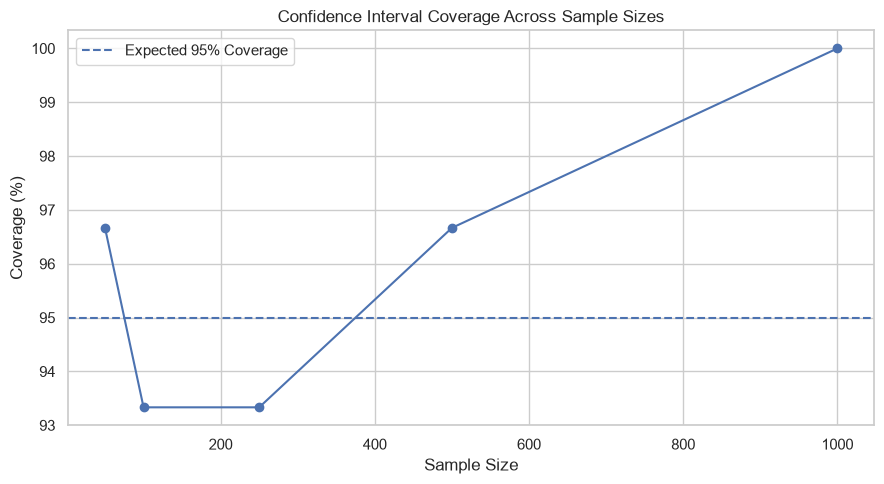

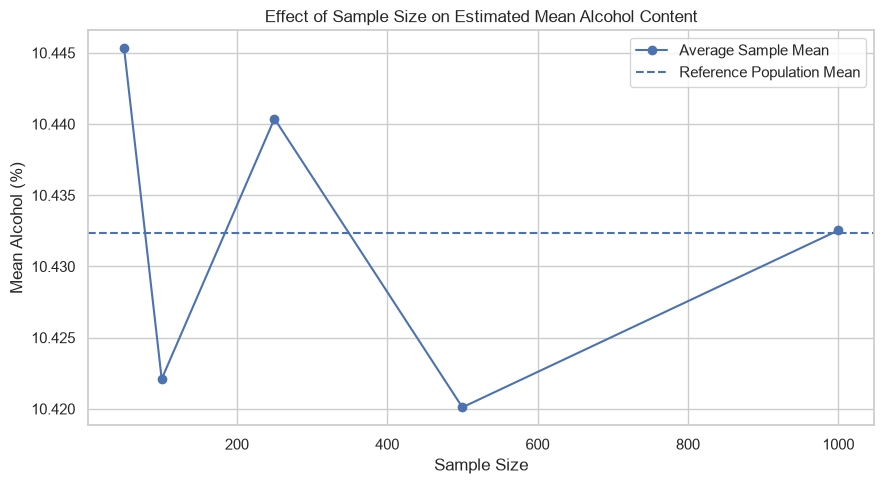

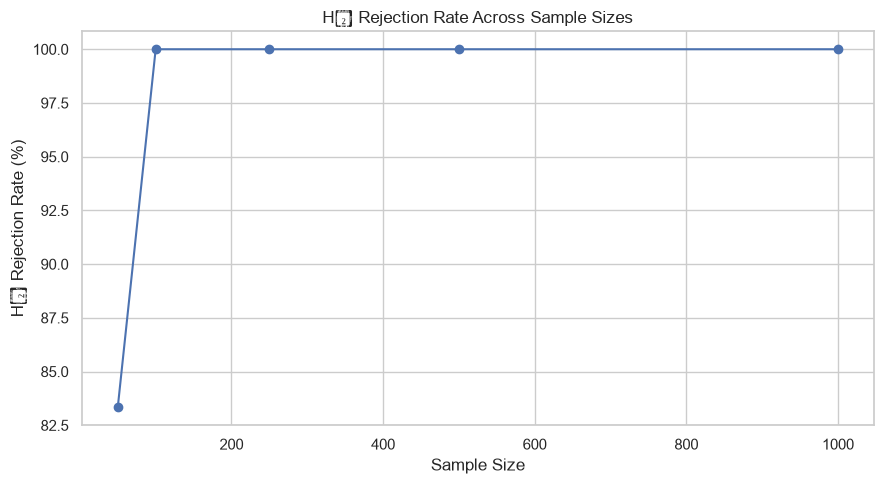

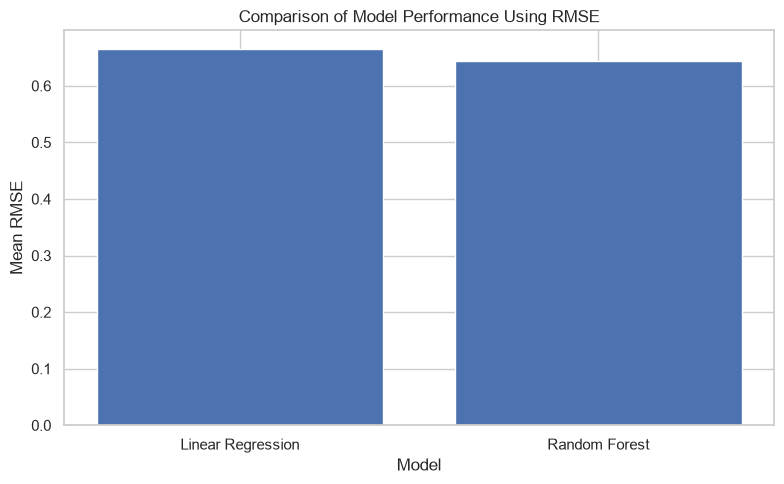

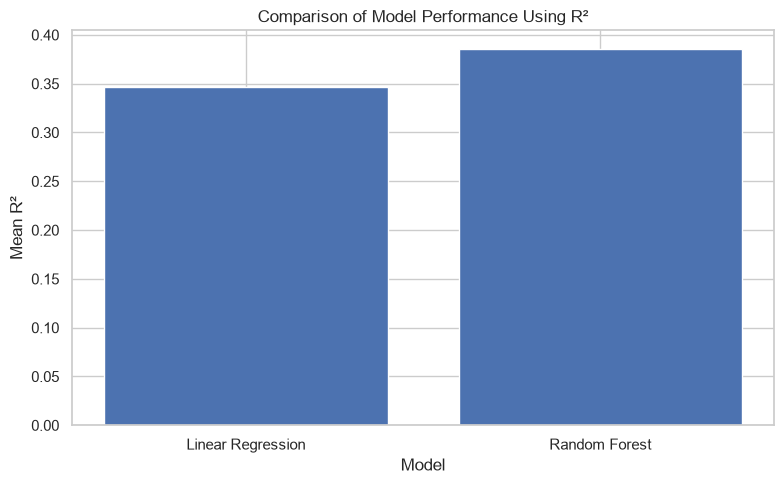

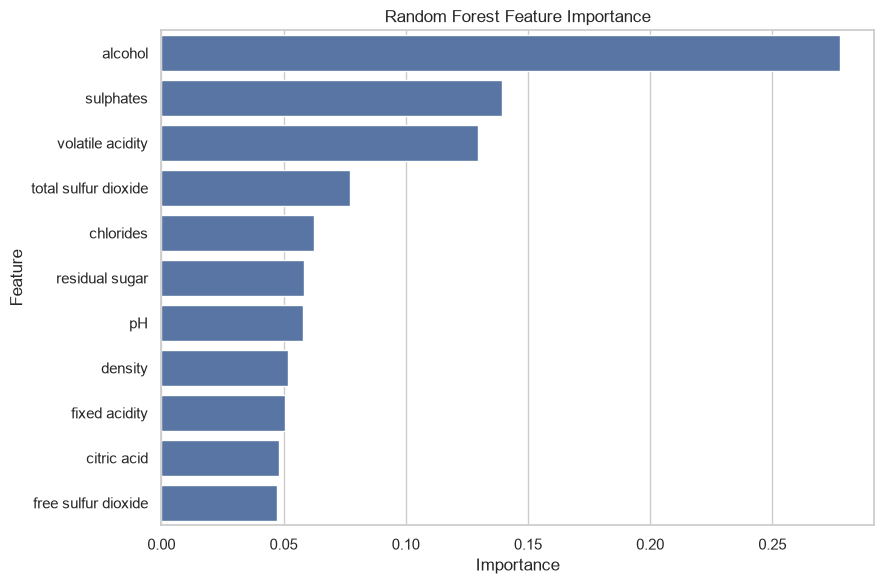

All final graphs have been saved successfully.


In [103]:
import os

os.makedirs("../graphs", exist_ok=True)

# --------------------------------------------------
# 1. Wine Quality Distribution
# --------------------------------------------------

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x="quality"
)

plt.title("Distribution of Wine Quality Scores")
plt.xlabel("Wine Quality")
plt.ylabel("Number of Samples")

plt.tight_layout()
plt.savefig("../graphs/01_quality_distribution.png", dpi=300, bbox_inches="tight")
plt.show()


# --------------------------------------------------
# 2. Distribution of Physicochemical Variables
# --------------------------------------------------

df_clean[features].hist(
    figsize=(15, 12),
    bins=20
)

plt.suptitle(
    "Distribution of Physicochemical Variables",
    fontsize=16
)

plt.tight_layout()
plt.savefig("../graphs/02_feature_distributions.png", dpi=300, bbox_inches="tight")
plt.show()


# --------------------------------------------------
# 3. Alcohol Content Across Quality Scores
# --------------------------------------------------

plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df_clean,
    x="quality",
    y="alcohol"
)

plt.title("Alcohol Content Across Wine Quality Scores")
plt.xlabel("Wine Quality")
plt.ylabel("Alcohol (%)")

plt.tight_layout()
plt.savefig("../graphs/03_alcohol_quality_boxplot.png", dpi=300, bbox_inches="tight")
plt.show()


# --------------------------------------------------
# 4. Low vs High Quality Alcohol
# --------------------------------------------------

plt.figure(figsize=(8, 6))

sns.boxplot(
    data=plot_data,
    x="Quality Group",
    y="alcohol"
)

plt.title("Alcohol Content: Low vs High Quality Wines")
plt.xlabel("Quality Group")
plt.ylabel("Alcohol (%)")

plt.tight_layout()
plt.savefig("../graphs/04_low_high_quality_boxplot.png", dpi=300, bbox_inches="tight")
plt.show()


# --------------------------------------------------
# 5. Alcohol vs Wine Quality
# --------------------------------------------------

plt.figure(figsize=(9, 6))

sns.regplot(
    data=df_clean,
    x="alcohol",
    y="quality",
    scatter_kws={"alpha": 0.4}
)

plt.title("Relationship Between Alcohol Content and Wine Quality")
plt.xlabel("Alcohol (%)")
plt.ylabel("Wine Quality")

plt.tight_layout()
plt.savefig("../graphs/05_alcohol_quality_scatter.png", dpi=300, bbox_inches="tight")
plt.show()


# --------------------------------------------------
# 6. Correlation Heatmap
# --------------------------------------------------

correlation_matrix = df_clean.corr(numeric_only=True)

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Wine Physicochemical Properties")

plt.tight_layout()
plt.savefig("../graphs/06_correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()


# --------------------------------------------------
# 7. Single-Sample Size CI Width
# --------------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    sample_size_results["Sample Size"],
    sample_size_results["CI Width"],
    marker="o"
)

plt.title("Effect of Sample Size on 95% Confidence Interval Width")
plt.xlabel("Sample Size")
plt.ylabel("Confidence Interval Width")

plt.tight_layout()
plt.savefig("../graphs/07_sample_size_ci_width.png", dpi=300, bbox_inches="tight")
plt.show()


# --------------------------------------------------
# 8. Repeated-Sampling Average CI Width
# --------------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    summary_table["Sample Size"],
    summary_table["Avg_CI_Width"],
    marker="o"
)

plt.title("Effect of Sample Size on Average 95% Confidence Interval Width")
plt.xlabel("Sample Size")
plt.ylabel("Average Confidence Interval Width")

plt.tight_layout()
plt.savefig("../graphs/08_repeated_ci_width.png", dpi=300, bbox_inches="tight")
plt.show()


# --------------------------------------------------
# 9. Confidence Interval Coverage
# --------------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    summary_table["Sample Size"],
    summary_table["CI_Coverage"],
    marker="o"
)

plt.axhline(
    95,
    linestyle="--",
    label="Expected 95% Coverage"
)

plt.title("Confidence Interval Coverage Across Sample Sizes")
plt.xlabel("Sample Size")
plt.ylabel("Coverage (%)")

plt.legend()

plt.tight_layout()
plt.savefig("../graphs/09_ci_coverage.png", dpi=300, bbox_inches="tight")
plt.show()


# --------------------------------------------------
# 10. Mean Stability
# --------------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    summary_table["Sample Size"],
    summary_table["Mean"],
    marker="o",
    label="Average Sample Mean"
)

plt.axhline(
    reference_mean,
    linestyle="--",
    label="Reference Population Mean"
)

plt.title("Effect of Sample Size on Estimated Mean Alcohol Content")
plt.xlabel("Sample Size")
plt.ylabel("Mean Alcohol (%)")

plt.legend()

plt.tight_layout()
plt.savefig("../graphs/10_mean_stability.png", dpi=300, bbox_inches="tight")
plt.show()


# --------------------------------------------------
# 11. H0 Rejection Rate
# --------------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    summary_table["Sample Size"],
    summary_table["H0_Rejection_Rate"],
    marker="o"
)

plt.title("H₀ Rejection Rate Across Sample Sizes")
plt.xlabel("Sample Size")
plt.ylabel("H₀ Rejection Rate (%)")

plt.tight_layout()
plt.savefig("../graphs/11_h0_rejection_rate.png", dpi=300, bbox_inches="tight")
plt.show()


# --------------------------------------------------
# 12. Model RMSE Comparison
# --------------------------------------------------

model_names = ["Linear Regression", "Random Forest"]

rmse_values = [
    linear_results_df["RMSE"].mean(),
    rf_results_df["RMSE"].mean()
]

plt.figure(figsize=(8, 5))

plt.bar(
    model_names,
    rmse_values
)

plt.title("Comparison of Model Performance Using RMSE")
plt.xlabel("Model")
plt.ylabel("Mean RMSE")

plt.tight_layout()
plt.savefig("../graphs/12_model_rmse.png", dpi=300, bbox_inches="tight")
plt.show()


# --------------------------------------------------
# 13. Model R² Comparison
# --------------------------------------------------

r2_values = [
    linear_results_df["R²"].mean(),
    rf_results_df["R²"].mean()
]

plt.figure(figsize=(8, 5))

plt.bar(
    model_names,
    r2_values
)

plt.title("Comparison of Model Performance Using R²")
plt.xlabel("Model")
plt.ylabel("Mean R²")

plt.tight_layout()
plt.savefig("../graphs/13_model_r2.png", dpi=300, bbox_inches="tight")
plt.show()


# --------------------------------------------------
# 14. Random Forest Feature Importance
# --------------------------------------------------

plt.figure(figsize=(9, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.savefig("../graphs/14_feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()


print("All final graphs have been saved successfully.")

Export all important tables

In [104]:
os.makedirs("../results", exist_ok=True)

# Descriptive statistics
descriptive_stats.round(4).to_csv(
    "../results/descriptive_statistics.csv"
)

# Single sample-size experiment
sample_size_results.round(4).to_csv(
    "../results/sample_size_analysis.csv",
    index=False
)

# Repeated sample-size experiment
summary_table.round(4).to_csv(
    "../results/repeated_sample_size_analysis.csv",
    index=False
)

# Linear regression CV results
linear_results_df.round(4).to_csv(
    "../results/linear_regression_cv.csv",
    index=False
)

# Random forest CV results
rf_results_df.round(4).to_csv(
    "../results/random_forest_cv.csv",
    index=False
)

# Model comparison
model_comparison.round(4).to_csv(
    "../results/model_comparison.csv"
)

# Feature importance
feature_importance.round(4).to_csv(
    "../results/feature_importance.csv",
    index=False
)

# Correlation matrix
correlation_matrix.round(4).to_csv(
    "../results/correlation_matrix.csv"
)

print("All statistical tables have been exported successfully.")

All statistical tables have been exported successfully.
